# D-6: How much of the recovery came from each change?
**Step 1 (arithmetic):** split repeat revenue (ARR's building block) into
*active repeat customers × purchase visits per customer × spend per purchase visit*, by age band.

**Step 2 (linear regression, event study):** how each customer's monthly spending moves before and after
joining loyalty or first using repairs, with every calendar month and every customer held fixed.

**Step 3:** can the website's effect on members be separated from the new manager?

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "text.parse_math": False,
})

WINDOWS = {
    "pre":    ("2023-03-01", "2024-02-01"),   # year before the competitor
    "trough": ("2024-03-01", "2025-02-01"),   # ARR at its Feb 2025 low = repeat revenue in these 12 months
    "latest": ("2025-11-01", "2026-10-01"),   # ARR at Oct 2026
}
WEBSITE = C.WEBSITE_LAUNCH.to_period("M").to_timestamp()      # Nov 2025
PLACEBO = pd.Timestamp("2024-11-01")                            # same month a year earlier: no event

visits = load("visits")
customers = load("customers")

## Step 1. Customers × visits × spend per visit
Each 12-month window covers every calendar month once, so seasonality and holiday sales cancel.
The log changes add up exactly: log(revenue) = log(customers) + log(visits per customer) + log(spend per visit).

In [2]:
rv = visits[visits["is_repeat_visit"]].merge(customers[["customer_id", "age_band"]], on="customer_id")


def window_stats(df, w):
    a, b = WINDOWS[w]
    d = df[(df["month"] >= a) & (df["month"] <= b)]
    # count purchase visits only: repair drop-off/pickup trips bring in $0 and didn't exist before Apr 2025
    return pd.Series({"revenue": d["revenue"].sum(), "customers": d["customer_id"].nunique(),
                      "visits": int(d["has_purchase"].sum())})


def decompose(df, w0, w1):
    s0, s1 = window_stats(df, w0), window_stats(df, w1)
    parts = pd.Series({
        "active repeat customers": np.log(s1.customers / s0.customers),
        "visits per customer": np.log((s1.visits / s1.customers) / (s0.visits / s0.customers)),
        "spend per visit": np.log((s1.revenue / s1.visits) / (s0.revenue / s0.visits)),
    }) * 100
    parts["total (log %)"] = parts.sum()
    parts["revenue change ($K)"] = (s1.revenue - s0.revenue) / 1e3
    return parts


rows = {"All customers": decompose(rv, "pre", "latest")}
for band in ["18-24", "25-34", "35-44", "45-54", "55+"]:
    rows[band] = decompose(rv[rv["age_band"] == band], "pre", "latest")
decomp = pd.DataFrame(rows).T.round(1)
print("Repeat revenue, Mar 2023–Feb 2024 vs Nov 2025–Oct 2026 (log %, parts add up to the total)")
decomp

Repeat revenue, Mar 2023–Feb 2024 vs Nov 2025–Oct 2026 (log %, parts add up to the total)


,active repeat customers,visits per customer,spend per visit,total (log %),revenue change ($K)
All customers,-19.7,28.4,-2.9,5.8,378.7
18-24,-73.3,14.0,-2.5,-61.9,-549.4
25-34,-12.5,26.4,-5.4,8.5,190.7
35-44,-1.5,36.9,-10.0,25.3,446.6
45-54,-3.1,32.9,-11.4,18.4,182.6
55+,0.6,25.6,-6.6,19.6,85.8


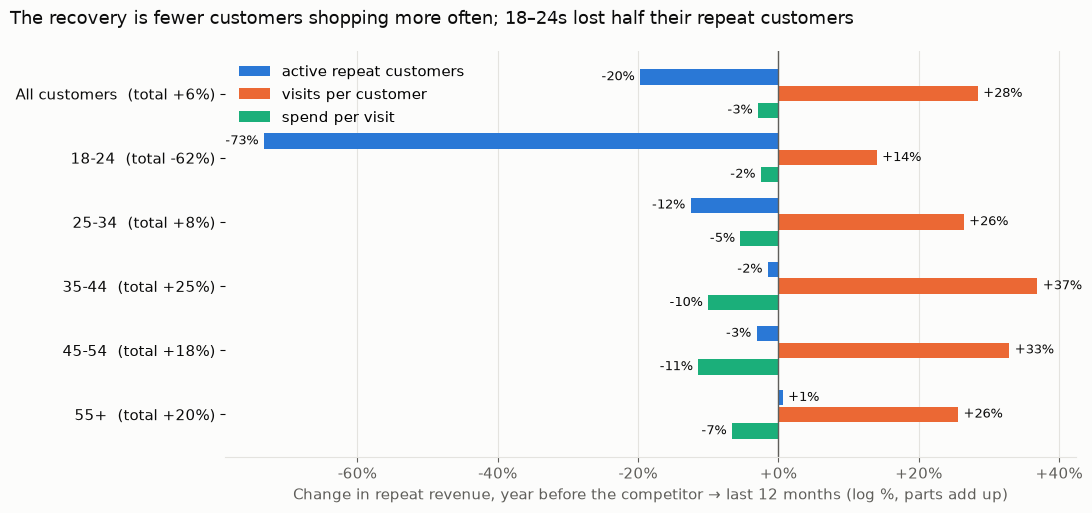

In [3]:
order = ["All customers", "18-24", "25-34", "35-44", "45-54", "55+"]
parts = ["active repeat customers", "visits per customer", "spend per visit"]
colors = [BLUE, ORANGE, AQUA]
fig, ax = plt.subplots(figsize=(11, 5.2))
y = np.arange(len(order))
h = 0.26
for k, (p, colr) in enumerate(zip(parts, colors)):
    vals = decomp.loc[order, p]
    bars = ax.barh(y + (k - 1) * h, vals, h * 0.92, color=colr, label=p)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:+.0f}%", (v, b.get_y() + b.get_height() / 2), xytext=(4 if v >= 0 else -4, 0),
                    textcoords="offset points", ha="left" if v >= 0 else "right", va="center", fontsize=9, color=INK)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, [f"{o}  (total {decomp.loc[o, 'total (log %)']:+.0f}%)" for o in order])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set_xlabel("Change in repeat revenue, year before the competitor → last 12 months (log %, parts add up)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", frameon=False)
fig.suptitle("The recovery is fewer customers shopping more often; 18–24s lost half their repeat customers",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "d6_decomposition.png", dpi=200)
plt.show()

## Step 2. What happens to spending before and after joining loyalty or first using repairs?
**Linear regression (event study)**, one row per customer per month (Pilates recruits excluded; they're
covered in D-2):

`spend[i,t] = Σ (dummies for months relative to joining) + Σ (dummies for months relative to first repair)`
`           + month dummy[t] + customer dummy[i]`

- **Month dummies** absorb everything that hit the whole store that month: competitor, season, holiday sales,
  website, new manager.
- **Customer dummies** compare each customer with themselves (applied by subtracting each customer's average).
- Each coefficient = extra monthly repeat spend in that window, vs the customer's own normal level and vs
  everyone else in the same calendar month. Standard errors clustered by customer.
- **Pre-trend check:** the "before" windows show whether spending was already changing before the event.

*Why not a single "loyalty effect" × exposure waterfall?* We tried it first (one "after joining" dummy, plus a
member × after-website term). It credited loyalty and repairs with more than the whole $1.15M recovery and gave
the website −$2M, because a single average can't capture an effect that rises and then fades. Its placebo
(member × after Nov 2024, a year before the website) was also negative. So we report how spending moves over time instead.

In [4]:
cm = load("customer_month")
pil_ids = set(customers.loc[customers["acquisition_channel"] == "Pilates Campaign", "customer_id"])
ev = customers.set_index("customer_id")[["loyalty_join_date", "first_repair_date"]].apply(
    lambda s: s.dt.to_period("M").dt.to_timestamp())
cm = cm.join(ev, on="customer_id")
cm = cm[~cm["customer_id"].isin(pil_ids)].reset_index(drop=True)
mo = cm["month"]

BINS = [(-6, -4, "6–4 before"), (-3, -1, "3–1 before"), (0, 0, "event month"), (1, 3, "1–3 after"),
        (4, 6, "4–6 after"), (7, 12, "7–12 after"), (13, 99, "13+ after")]
X = pd.DataFrame(index=cm.index)
for name, col in [("Loyalty", "loyalty_join_date"), ("Repairs", "first_repair_date")]:
    e = cm[col]
    k = (mo.dt.year - e.dt.year) * 12 + (mo.dt.month - e.dt.month)
    for lo, hi, lab in BINS:
        X[f"{name}|{lab}"] = ((k >= lo) & (k <= hi)).astype(float)
TERMS = list(X.columns)
X = pd.concat([X, pd.get_dummies(mo, prefix="m", drop_first=True, dtype=float)], axis=1)
y = cm["repeat_revenue"].astype(float)
g = cm["customer_id"]
Xd = X - X.groupby(g).transform("mean")
yd = y - y.groupby(g).transform("mean")
es = sm.OLS(yd, Xd).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(g)[0]})

event = pd.DataFrame({"extra $ per month": es.params[TERMS], "95% low": es.conf_int().loc[TERMS, 0],
                      "95% high": es.conf_int().loc[TERMS, 1]})
event.index = pd.MultiIndex.from_tuples([t.split("|") for t in TERMS], names=["program", "window"])
print(f"{len(cm):,} customer-months, {g.nunique():,} customers")
event.round(1)

457,780 customer-months, 14,080 customers


extra $ per month  95% low  95% high
program window                                           
Loyalty 6–4 before                12.0      7.7      16.4
        3–1 before               -20.4    -24.1     -16.6
        event month              102.1     96.6     107.7
        1–3 after                 36.3     32.2      40.4
        4–6 after                 41.6     36.8      46.5
        7–12 after                 4.6      0.3       9.0
        13+ after                -14.0    -19.3      -8.8
Repairs 6–4 before                46.0     38.4      53.7
        3–1 before                30.8     24.4      37.1
        event month              197.0    185.0     208.9
        1–3 after                 92.6     84.6     100.6
        4–6 after                 88.0     79.2      96.8
        7–12 after                69.3     61.1      77.5
        13+ after                 59.4     47.9      70.8

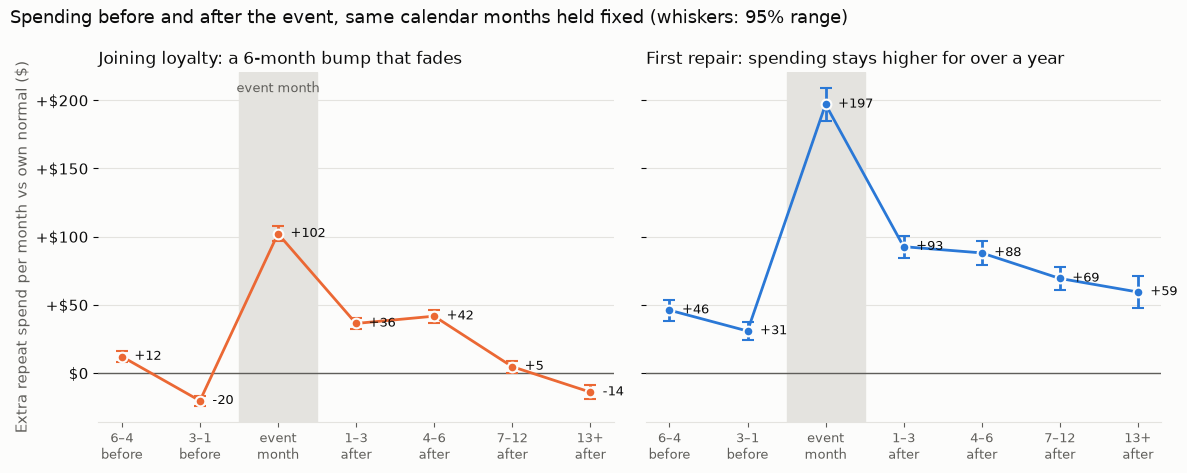

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
labs = [b[2] for b in BINS]
xs = np.arange(len(labs))
for ax, (prog, colr, ttl) in zip(axes, [("Loyalty", ORANGE, "Joining loyalty: a 6-month bump that fades"),
                                        ("Repairs", BLUE, "First repair: spending stays higher for over a year")]):
    d = event.loc[prog].reindex(labs)
    ax.axhline(0, color=INK2, lw=1)
    ax.axvspan(1.5, 2.5, color=GRID, zorder=0)
    ax.errorbar(xs, d["extra $ per month"], yerr=[d["extra $ per month"] - d["95% low"], d["95% high"] - d["extra $ per month"]],
                color=colr, marker="o", ms=7, lw=2, capsize=4, mec="#fcfcfb", mew=1.5)
    for x, v in zip(xs, d["extra $ per month"]):
        ax.annotate(f"{v:+.0f}", (x, v), xytext=(9, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_xticks(xs, [l.replace(" ", "\n", 1) for l in labs], fontsize=9)
    ax.set_title(ttl, loc="left", color=INK, fontsize=12)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Extra repeat spend per month vs own normal ($)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: (f"+${v:.0f}" if v > 0 else f"−${-v:.0f}") if v else "$0"))
axes[0].text(2, axes[0].get_ylim()[1] * 0.97, "event month", ha="center", va="top", fontsize=9, color=INK2)
fig.suptitle("Spending before and after the event, same calendar months held fixed (whiskers: 95% range)",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "d6_event_study.png", dpi=200)
plt.show()

## Step 3. Website vs new manager: members after Nov 2025
The website shows loyalty tier and points, so if it changed anything it should change members more than
non-members. Add "member (joined before Nov 2024) × after Nov 2025" to the event study, with the same term
a year earlier as a **placebo** (no event in Nov 2024). Using only long-standing members keeps the 6-month
joining bump out of both terms.

In [6]:
long_member = (cm["loyalty_join_date"] < PLACEBO).astype(float)
X2 = X.copy()
X2["long member × after Nov 2025 (website)"] = long_member * (mo >= WEBSITE)
X2["long member × after Nov 2024 (placebo)"] = long_member * (mo >= PLACEBO)
web_terms = ["long member × after Nov 2025 (website)", "long member × after Nov 2024 (placebo)"]
X2d = X2 - X2.groupby(g).transform("mean")
ws = sm.OLS(yd, X2d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(g)[0]})
website = pd.DataFrame({"extra $ per month": ws.params[web_terms], "95% low": ws.conf_int().loc[web_terms, 0],
                        "95% high": ws.conf_int().loc[web_terms, 1], "p-value": ws.pvalues[web_terms]})
website.round(2)

,extra $ per month,95% low,95% high,p-value
long member × after Nov 2025 (website),-18.79,-22.87,-14.72,0.0
long member × after Nov 2024 (placebo),8.47,3.37,13.58,0.0


## Caveats
- **Observational.** Customer and month dummies remove fixed differences and store-wide events, but not reasons
  for joining that coincide with a shopping spree. The "before" windows show this: repair users were already
  spending more before their first repair (self-selection), and people dip just before joining, then join during
  a big purchase.
- **Website vs new manager:** only the website's effect *on members* can be tested, and only if it beats the
  placebo. The new manager, and the website's effect on everyone, can't be separated from other store-wide changes.
- A dollar-by-dollar split of the recovery between programs isn't credible with this data (see the note in Step 2).